**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**01 | Biomechanical Data Foundation and Provenance Audit**

**Objective:** Establish the source identity, integrity, participant-level structure and finite-element (FE) target representation of the original Essex femoral-neck-loading dataset before attempting regression or model selection.

**Dataset:** Hollinger et al., *Scientific Data* (2026), DOI [10.1038/s41597-026-07429-3](https://doi.org/10.1038/s41597-026-07429-3); [Figshare article 30225739, version 13](https://doi.org/10.6084/m9.figshare.30225739). The full archive is distinct from the authors' 444-record walking/running BoneNet derivative.

**Notebook scope:** Retrieve the pinned published MATLAB archive in Google Colab; verify checksums and ZIP contents; inspect 40 participant MAT files, source-field availability and representation of `e1e3`; describe the audited cohort without inferring record-to-person mappings or physical units; save reproducible inventories, a study-quality figure and a provenance record.

**Boundary:** A valid MATLAB field or nonempty MATLAB object is not yet a verified, finite-valued strain trajectory. No FE computation, model fitting, participant-independent evaluation or clinical validation is performed. A stage-specific SVG will be added after scientific execution and approval.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}


# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")


# ---------------------------- 2. Standard Library ----------------------------
import json
from pathlib import Path


# ----------------- 3. Scientific Computing and Data Analysis -----------------
import pandas as pd


# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))


# ----------------------- 5. Shared and Study Utilities -----------------------
from core.output_download import download_outputs_from_colab
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, ensure_source_file,
    extract_matlab_files, fetch_version_manifest,
    find_published_file, inspect_matlab_archive, inspect_subject_mat,
)


# ---------------- 6. Raw Data and Research Output Directories ----------------
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
output_dir = root / "biomechanical_load_estimation" / "output"
raw_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)
print("Pinned Figshare article:", ARTICLE_ID, "| Version:", ARTICLE_VERSION)
print("Research output directory:", output_dir)

Pinned Figshare article: 30225739 | Version: 13
Research output directory: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Pinned Source Identity and Published File Manifest**

The Figshare public API supplies version-specific article metadata and downloadable file identities. This step records filenames, file IDs, sizes, URLs and published MD5 digests where available. Choosing version 13 prevents silently switching to a later dataset revision. A successful metadata request does not establish the integrity of the archive bytes, which is checked separately.

In [3]:
# =============== 02. Pinned Figshare Article and File Manifest ===============

# ------------------- 1. Retrieve Official Version Metadata -------------------
article, source_files = fetch_version_manifest()
archive_file = find_published_file(source_files, "MATLAB.zip")
source_table = pd.DataFrame([
    {
        "file_id": item.get("id"),
        "filename": item.get("name"),
        "size_bytes": item.get("size"),
        "download_url": item.get("download_url"),
        "published_md5": item.get("computed_md5") or item.get("supplied_md5"),
    }
    for item in source_files
])
display(source_table)


# -------------------- 2. Record Original Dataset Identity --------------------
metadata = {
    "article_id": ARTICLE_ID,
    "version": ARTICLE_VERSION,
    "title": article.get("title"),
    "doi": article.get("doi"),
    "published_date": article.get("published_date"),
    "license": article.get("license"),
    "archive_file_id": archive_file["id"],
    "archive_filename": archive_file["name"],
    "archive_size_bytes": archive_file["size"],
    "archive_published_md5": archive_file.get("computed_md5") or archive_file.get("supplied_md5"),
}
source_table.to_csv(output_dir / "01_figshare_file_manifest.csv", index=False)
print("Article:", metadata["title"])
print("Pinned archive:", metadata["archive_filename"])
print("Archive size (MiB):", round(metadata["archive_size_bytes"] / 1024**2, 2))

,file_id,filename,size_bytes,download_url,published_md5
0,63190519,OpenSim.zip,10904670,https://ndownloader.figshare.com/files/63190519,a1d002db6f1d77eef9c0fe3d5f8ea78f
1,63190690,MATLAB.zip,235590610,https://ndownloader.figshare.com/files/63190690,1b1c94eb552ba11f1c5521ec9ef49b96
2,63341380,Visual3D.zip,19308519333,https://ndownloader.figshare.com/files/63341380,de426331d951f1ed52feb0713700f837
3,63342400,SubCharacteristics.xlsx,29700,https://ndownloader.figshare.com/files/63342400,cbd5ebc13efca8efbba0dd644e5056ef
4,63342406,angles.xlsx,31175261,https://ndownloader.figshare.com/files/63342406,3a695d26a6d67f0f682628ed7b2911c2
5,63343417,README.md,7728,https://ndownloader.figshare.com/files/63343417,a43306a8db24a33b55ade29421bb628c


Article: Dataset for Rapid Estimation of Femoral Neck Loading During Gait and Dynamic Exercises
Pinned archive: MATLAB.zip
Archive size (MiB): 224.68


**03. Official Archive Acquisition and ZIP Integrity**

Download only `MATLAB.zip`, not the full Figshare collection. The helper checks the declared byte count and the official MD5 when supplied, computes a local SHA256 and validates every ZIP member's path and CRC before extraction. Existing raw files are reused only if their identity checks succeed. All downloaded raw bytes stay in the git-ignored `data/raw/` directory.

In [4]:
# ============ 03. Controlled Source Download and ZIP Verification ============

# --------------- 1. Download and Verify Official Source Bytes ----------------
archive_path, archive_hashes = ensure_source_file(archive_file, raw_dir)
print("Archive:", archive_path)
print("Verified local SHA256:", archive_hashes["sha256"])


# --------------------- 2. Validate the Complete Archive ----------------------
zip_records = inspect_matlab_archive(archive_path, expected_mat_files=40)
archive_table = pd.DataFrame(zip_records)
display(archive_table.head(10))
archive_table.to_csv(output_dir / "01_matlab_archive_inventory.csv", index=False)
print("Verified MATLAB files:", int(archive_table["is_matlab_file"].sum()))
print("Total uncompressed MiB:", round(archive_table["size_bytes"].sum() / 1024**2, 2))

Archive: /content/human-movement-intelligence/data/raw/essex_femoral_neck_loading/MATLAB.zip
Verified local SHA256: c50f10d1364686412b7ab64cac435dc85864dc8dbb34d2804b9cf37f2e29132d


,filename,size_bytes,compressed_bytes,is_matlab_file
0,MATLAB/,0,0,False
1,MATLAB/Processed Data/,0,0,False
2,MATLAB/Processed Data/subj04.mat,5950822,5947433,True
3,MATLAB/Processed Data/subj05.mat,5952359,5949100,True
4,MATLAB/Processed Data/subj06.mat,5960044,5956881,True
5,MATLAB/Processed Data/subj08.mat,5947583,5944209,True
6,MATLAB/Processed Data/subj09.mat,5218815,5215844,True
7,MATLAB/Processed Data/subj10.mat,5968410,5964994,True
8,MATLAB/Processed Data/subj11.mat,4980060,4977585,True
9,MATLAB/Processed Data/subj12.mat,5841830,5838897,True


Verified MATLAB files: 40
Total uncompressed MiB: 224.79


**04. Participant-Level File Extraction and Source Inventory**

Only the 40 validated MATLAB members are extracted. Filenames, not consecutive integers or spreadsheet row positions, determine the observed participant inventory. No assignment of movement cycles to labels or modelling splits is made here. This section preserves the archive's identity for subsequent provenance checks.

In [5]:
# =========== 04. MATLAB File Inventory and Participant Identifiers ===========

# -------------------- 1. Extract Validated MATLAB Members --------------------
mat_paths = extract_matlab_files(archive_path, mat_dir, zip_records)
participant_ids = [path.stem.lower() for path in mat_paths]
assert len(mat_paths) == len(set(participant_ids)) == 40
assert all(path.stat().st_size > 0 for path in mat_paths)


# ------------------- 2. Inspect Explicit Source Filenames --------------------
participant_table = pd.DataFrame({
    "source_file": [path.name for path in mat_paths],
    "subject_id": participant_ids,
    "file_size_bytes": [path.stat().st_size for path in mat_paths],
})
display(participant_table)
participant_table.to_csv(output_dir / "01_matlab_participant_inventory.csv", index=False)
print("Independent source files:", len(participant_table))
print("IDs are observed from filenames, not generated by range.")

,source_file,subject_id,file_size_bytes
0,subj04.mat,subj04,5950822
1,subj05.mat,subj05,5952359
2,subj06.mat,subj06,5960044
3,subj08.mat,subj08,5947583
4,subj09.mat,subj09,5218815
5,subj10.mat,subj10,5968410
6,subj11.mat,subj11,4980060
7,subj12.mat,subj12,5841830
8,subj13.mat,subj13,5966244
9,subj14.mat,subj14,5224338


Independent source files: 40
IDs are observed from filenames, not generated by range.


**05. Original MATLAB Record Schema and Field Coverage**

Inspect the original `Data` variable in each participant MAT file. The source archives can contain structured and opaque MATLAB objects. This audit counts the recorded elements and available first-record fields, but it does **not** reinterpret object metadata as IMU measurements or FE target waveforms. Any decoding or file-reading failure must remain visible.

In [6]:
# ============== 05. Participant-Level MATLAB Data Schema Audit ===============

# --------------------- 1. Inspect Every Source MAT File ----------------------
audit_rows = []
for source_path in mat_paths:
    audit_rows.append(inspect_subject_mat(source_path))

audit_table = pd.DataFrame(audit_rows).sort_values("subject_id").reset_index(drop=True)
display(audit_table[[
    "subject_id", "record_count", "source_data_shape",
    "first_record_type", "field_names_first_record"
]].head(12))


# ---------------- 2. Save Source Representation and Coverage -----------------
audit_table.to_csv(output_dir / "01_matlab_record_schema_audit.csv", index=False)
print("Participants audited:", len(audit_table))
print("Total MATLAB Data records:", int(audit_table["record_count"].sum()))
print("Record counts by participant:")
display(audit_table[["subject_id", "record_count"]])

,subject_id,record_count,source_data_shape,first_record_type,field_names_first_record
0,subj04,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
1,subj05,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
2,subj06,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
3,subj08,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
4,subj09,42,"(42, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
5,subj10,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
6,subj11,40,"(40, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
7,subj12,47,"(47, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
8,subj13,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
9,subj14,42,"(42, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...


Participants audited: 40
Total MATLAB Data records: 1897
Record counts by participant:


,subject_id,record_count
0,subj04,48
1,subj05,48
2,subj06,48
3,subj08,48
4,subj09,42
5,subj10,48
6,subj11,40
7,subj12,47
8,subj13,48
9,subj14,42


**06. Finite-Element Strain Representation and Participant Metadata**

For each original `Data` record, the audit distinguishes missing or empty `e1e3` fields, numeric candidate arrays, non-finite numeric arrays and unresolved MATLAB-object representations. A nonempty opaque object remains **unverified**, and an array classified as a numeric candidate still requires a later scientific check of `e1/e3` ordering, unit convention and temporal alignment.

The pinned Figshare participant workbook must contain exactly 40 distinct source-coded participant IDs matching the 40 MATLAB filenames. Read only its participant identifier column; do not export demographic or free-text health-history fields. Aggregate rows must not be counted as participants.

In [ ]:
# =========== 06. FE Target Representation and Participant Metadata ===========

# ------------------ 1. Summarise FE Target Representations -------------------
status_cols = [
    "numeric_candidate", "empty", "missing_field",
    "nonfinite_numeric", "matlab_object_unresolved",
    "non_numeric_unresolved",
]
target_table = audit_table[["subject_id", "record_count", *status_cols]].copy()
target_table.to_csv(output_dir / "01_femoral_strain_representation.csv", index=False)
display(target_table)
print("FE representation totals:")
display(target_table[status_cols].sum().rename("records").to_frame())


# --------- 2. Inspect Published Participant Workbook When Available ----------
workbook_items = [
    item for item in source_files
    if item.get("name", "").lower() == "subcharacteristics.xlsx"
]
if len(workbook_items) != 1:
    raise ValueError(
        "Expected one SubCharacteristics.xlsx in the pinned Figshare version."
    )

workbook_path, workbook_hashes = ensure_source_file(workbook_items[0], raw_dir)
workbook = pd.read_excel(workbook_path)
if "Participent ID" not in workbook.columns:
    raise ValueError("Expected source participant-ID header is absent.")

ids = workbook["Participent ID"].astype("string").str.strip()
observed = ids[ids.str.fullmatch(r"(?i)subj\d+", na=False)]
workbook_subjects = sorted(observed.str.lower().unique().tolist())
workbook_status = "VERIFIED PARTICIPANT ID COLUMN"
workbook_id_match = (
    len(observed) == 40
    and len(workbook_subjects) == 40
    and set(workbook_subjects) == set(participant_ids)
)
print("Workbook participant rows:", len(observed))
print("Workbook participant IDs:", len(workbook_subjects))
print("Workbook / MAT ID agreement:", workbook_id_match)
if not workbook_id_match:
    raise ValueError(
        "Workbook participants do not match the 40 MATLAB source files."
    )

**07. Descriptive Quality Profile**

The figure summarises the number of recorded MATLAB `Data` elements per participant and the *representation classes* of the `e1e3` field. These are source-structure diagnostics, not reconstructed strain trajectories or model results. Figure production uses the repository's approved Matplotlib style and export helper.

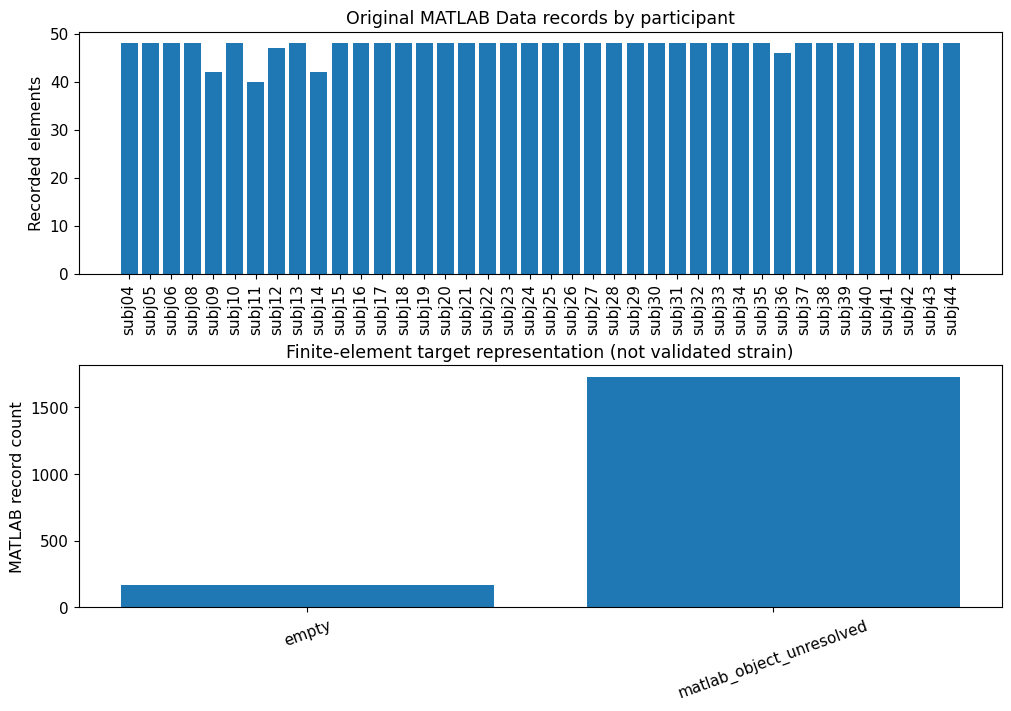

In [8]:
# =========== 07. Participant Coverage and FE Representation Figure ===========

# -------------- 1. Display Source Data Elements by Participant ---------------
fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
axes[0].bar(audit_table["subject_id"], audit_table["record_count"])
axes[0].set_title("Original MATLAB Data records by participant")
axes[0].set_ylabel("Recorded elements")
axes[0].tick_params(axis="x", labelrotation=90)


# --------------- 2. Display Verified Representation Categories ---------------
status_total = target_table[status_cols].sum()
status_total = status_total[status_total > 0]
axes[1].bar(status_total.index, status_total.values)
axes[1].set_title("Finite-element target representation (not validated strain)")
axes[1].set_ylabel("MATLAB record count")
axes[1].tick_params(axis="x", labelrotation=20)
axes[1].set_ylim(bottom=0)
save_figure(fig, output_dir / "01_source_quality_overview.png")
plt.show()

**08. Scientific Quality Gate and Source Provenance**

The stage may pass its **archive-and-record-structure gate** only after checking the pinned version, the 40 distinct participant files, mandatory matching IDs in the participant workbook, nonempty `Data` arrays, unique source IDs and complete record/target-status accounting. This does not authorise regression training: numerical FE decoding, source units, temporal alignment and a leakage-safe participant/trial registry remain separate scientific requirements.

The output JSON records exact file digests and distinguishes structural success from model readiness. No research results are invented or imported from the exploratory derivative baseline.

In [ ]:
# ============= 08. Source Provenance and Scientific Quality Gate =============

# --------------- 1. Validate the Audited Source Representation ---------------
assert ARTICLE_ID == 30225739 and ARTICLE_VERSION == 13
assert len(mat_paths) == 40 and len(set(participant_ids)) == 40
assert audit_table["record_count"].gt(0).all()
assert audit_table["subject_id"].is_unique
assert int(target_table[status_cols].sum().sum()) == int(audit_table["record_count"].sum())
assert set(audit_table["subject_id"]) == set(participant_ids)

assert workbook_status == "VERIFIED PARTICIPANT ID COLUMN"
assert workbook_id_match, "Workbook and MATLAB participant IDs do not match."
assert len(workbook_subjects) == 40


# --------- 2. Record Source Fingerprints and Open Research Questions ---------
provenance = {
    **metadata,
    "archive_sha256": archive_hashes["sha256"],
    "archive_md5": archive_hashes["md5"],
    "participant_mat_files": int(len(mat_paths)),
    "matlab_data_elements": int(audit_table["record_count"].sum()),
    "fe_representation_counts": {
        name: int(target_table[name].sum()) for name in status_cols
    },
    "per_file_sha256": dict(zip(
        audit_table["source_file"], audit_table["source_sha256"]
    )),
    "participant_workbook": workbook_status,
    "participant_workbook_sha256": workbook_hashes["sha256"],
    "workbook_participant_ids": len(workbook_subjects),
    "workbook_mat_id_alignment": workbook_id_match,
    "source_structure_quality_gate": "PASSED",
    "numeric_fe_waveform_validation": "NOT VERIFIED",
    "imu_physical_units": "NOT VERIFIED",
    "fe_temporal_alignment": "NOT VERIFIED",
    "subject_trial_mapping_for_regression": "NOT VERIFIED",
    "model_training_performed": False,
    "subject_independent_validation_performed": False,
}
(output_dir / "01_source_provenance_and_quality_gate.json").write_text(
    json.dumps(provenance, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)
print("STAGE 01 | SOURCE STRUCTURE QUALITY GATE: PASSED")
print("MODEL-READINESS QUALITY GATE: BLOCKED — FE decoding and linkage unresolved.")
print("Training or evaluation performed: NO")

**09. Save and Retrieve Recorded Research Evidence**

After the workbook-to-MAT identity check and the scientific Quality Gate have passed, package the refreshed recorded evidence. All research outputs use the `01_` prefix in `biomechanical_load_estimation/output/`. Downloading the stage-specific ZIP from Colab is a separate manual step. This cell does not push data or outputs to GitHub; raw MATLAB files remain under `data/raw/` and must not be committed.

**Scientific interpretation:** Successful execution documents source-archive integrity and source-record structure only. Stage 02 must resolve FE target decoding, units, temporal alignment and trial identities before constructing a model-ready dataset.

In [ ]:
# =============== 09. Stage 01 Output Register and Colab Export ===============

# ---------------------- 1. Check Recorded Stage Outputs ----------------------
stage_files = sorted(path for path in output_dir.glob("01_*") if path.is_file())
for path in stage_files:
    print(path.name, "|", f"{path.stat().st_size:,} bytes")
assert len(stage_files) >= 7


# ------------- 2. Package Research Outputs for Manual Retrieval --------------
download_outputs_from_colab(folder="biomechanical_load_estimation/output", stage="01")